# Bigger Audience, Smaller Share? Engagement Across News Outlets on Bluesky

Jonathan Satina

October 14, 2026

I used AI to help clean up the writing and to check that my code runs correctly.

**Hypothesis:** Among news outlet accounts on Bluesky, accounts with more followers get more likes per post on average, but they get fewer likes relative to the size of their audience, so engagement per follower goes down as follower count goes up.

## Theoretical and Statistical Applications

The idea behind this is that a big following doesn't mean a big active audience. Large outlets pick up a lot of people who follow once and then mostly scroll past, while smaller outlets tend to have more dedicated readers who interact. If that's true on Bluesky, then raw likes would make the biggest outlets look like they're doing the best when a smaller outlet might actually be connecting with its audience more, which matters for how news organizations judge whether a newer platform is worth their time.

The hypothesis is two relationships, a positive one between followers and average likes and a negative one between followers and likes per 1,000 followers. Follower counts are heavily skewed and the sample is small, so rank correlation and log scale plots make more sense here than a straight Pearson correlation.

## Variables

The independent variable is follower count from each account's profile. The dependent variables are average likes per post and likes per 1,000 followers, both built from the like counts on each account's recent posts. Supporting variables include median likes, average reposts and replies, the number of posts collected, total post count, and the date range the collected posts cover.

## Endpoints

**app.bsky.actor.getProfile** returns one account's profile per request, so I loop through the list of outlets and call it for each one. From each response I use `handle`, `displayName`, `followersCount`, `followsCount`, and `postsCount`, which gives the audience size for every outlet.

**app.bsky.feed.getAuthorFeed** returns up to 100 posts per request for one account, with a `cursor` for the next page. Each item in `feed` has a `post` object with `likeCount`, `repostCount`, `replyCount`, `quoteCount`, and a `record` holding the text and `createdAt` date. Items that are reposts of someone else's content include a `reason` key, so those get dropped, and the `posts_no_replies` filter keeps replies out so the data is just each outlet's own posts.

Together these work for the hypothesis because one endpoint gives the audience size and the other gives the engagement those posts actually got, and they share the `handle` field so they can be merged.

## Reliability and Limitations

The counts come straight from Bluesky's public AppView, need no login, and are the same for anyone who requests them, so the data is consistent and easy to repeat. The weak spots are that the numbers keep changing, so the newest posts haven't finished collecting likes yet, and follower counts can include inactive or bot accounts that would never engage anyway.

The biggest gap is that the API has no impressions or view counts, so there's no way to know how many followers actually saw a post, and likes per follower is only a stand in for real engagement rate. Pulling the 200 most recent posts also covers different stretches of time for different outlets, since a high volume account might fill that in a few days while a slower one takes weeks. The accounts were picked by hand instead of sampled randomly, deleted posts won't show up, and some outlets may run automated link posting that drags their averages down. With only a handful of accounts, any pattern here is a hint and not proof.

## Data Source and Structure

All data comes from the Bluesky public API at public.api.bsky.app. Each outlet's profile is requested with getProfile, the fields I need are sent to a list, and that list becomes a DataFrame with one row per outlet. Each outlet's feed is pulled in up to two pages with getAuthorFeed, reposts are removed, and each outlet's posts become their own DataFrame before all of them are stacked with `pd.concat()` into one post level DataFrame. That gets grouped by handle to get average engagement per account, merged with the profile data on `handle` using `pd.merge()`, and then likes per 1,000 followers is added, leaving a final table with one row per outlet.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time

In [2]:
url = "https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile"
params = {
    "actor": "nytimes.com"
}

response = requests.get(url, params=params)
response.status_code

200

In [3]:
response.url

'https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile?actor=nytimes.com'

In [4]:
response.raise_for_status()
data = response.json()
print(data.keys())

dict_keys(['did', 'handle', 'displayName', 'avatar', 'associated', 'labels', 'createdAt', 'verification', 'description', 'indexedAt', 'banner', 'followersCount', 'followsCount', 'postsCount'])


In [5]:
handles = [
    "nytimes.com", "washingtonpost.com", "npr.org", "theguardian.com",
    "apnews.com", "propublica.org", "theatlantic.com", "wired.com",
    "theverge.com", "motherjones.com", "newyorker.com", "latimes.com",
    "bloomberg.com", "wsj.com", "cnn.com", "axios.com"
]

In [6]:
profiles = []

for handle in handles:
    params = {"actor": handle}
    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        profiles.append({
            "handle": data["handle"],
            "display_name": data.get("displayName", ""),
            "followers": data["followersCount"],
            "following": data["followsCount"],
            "total_posts": data["postsCount"]
        })
    else:
        print(handle, response.status_code)
    time.sleep(0.25)

profiles_df = pd.DataFrame(profiles)
profiles_df

,handle,display_name,followers,following,total_posts
0,nytimes.com,The New York Times,1352860,123,44559
1,washingtonpost.com,The Washington Post,874217,149,26353
2,npr.org,NPR,1013194,238,19309
3,theguardian.com,The Guardian,794590,235,63839
4,apnews.com,The Associated Press,355283,0,20159
5,propublica.org,ProPublica,647635,361,7362
6,theatlantic.com,The Atlantic,404172,81,19401
7,wired.com,WIRED,483482,82,11922
8,theverge.com,The Verge,377959,141,15931
9,motherjones.com,Mother Jones,375963,127,12130


In [7]:
feed_url = "https://public.api.bsky.app/xrpc/app.bsky.feed.getAuthorFeed"
params = {
    "actor": "nytimes.com",
    "limit": 100,
    "filter": "posts_no_replies"
}

response = requests.get(feed_url, params=params)
response.status_code

200

In [8]:
response.raise_for_status()
feed_data = response.json()
print(feed_data.keys())

dict_keys(['feed', 'cursor'])


In [9]:
print(feed_data["feed"][0]["post"].keys())

dict_keys(['uri', 'cid', 'author', 'record', 'embed', 'bookmarkCount', 'replyCount', 'repostCount', 'likeCount', 'quoteCount', 'indexedAt', 'labels'])


In [10]:
post_frames = []

for handle in profiles_df["handle"]:
    posts = []
    cursor = None
    for page in range(2):
        params = {"actor": handle, "limit": 100, "filter": "posts_no_replies"}
        if cursor:
            params["cursor"] = cursor
        response = requests.get(feed_url, params=params)
        if response.status_code != 200:
            print(handle, response.status_code)
            break
        feed_data = response.json()
        posts += [item["post"] for item in feed_data["feed"] if "reason" not in item]
        cursor = feed_data.get("cursor")
        if cursor is None:
            break
        time.sleep(0.25)

    post_frames.append(pd.DataFrame([
        {
            "handle": handle,
            "uri": post["uri"],
            "created_at": post["record"].get("createdAt"),
            "text": post["record"].get("text", ""),
            "has_embed": "embed" in post,
            "likes": post.get("likeCount", 0),
            "reposts": post.get("repostCount", 0),
            "replies": post.get("replyCount", 0),
            "quotes": post.get("quoteCount", 0)
        }
        for post in posts
    ]))

In [11]:
posts_df = pd.concat(post_frames, ignore_index=True)
posts_df["created_at"] = pd.to_datetime(posts_df["created_at"], utc=True, errors="coerce", format="ISO8601")
print(posts_df.shape)
posts_df.head()

(2940, 9)


,handle,uri,created_at,text,has_embed,likes,reposts,replies,quotes
0,nytimes.com,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...,2026-10-21 17:10:02.857382+00:00,"Socialism, once deeply unpopular in the U.S., ...",True,6,1,2,0
1,nytimes.com,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...,2026-10-21 16:55:04.229890+00:00,It’s by now a cultural cliché to love Cardi B ...,True,7,1,2,0
2,nytimes.com,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...,2026-10-21 16:46:40.894385+00:00,Breaking News: The Supreme Court temporarily b...,True,52,9,4,3
3,nytimes.com,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...,2026-10-21 16:40:04.178838+00:00,In @nytopinion.nytimes.com \n\n“If the Trump a...,True,33,24,7,1
4,nytimes.com,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...,2026-10-21 16:25:07.475642+00:00,"Russia on Wednesday released Stephen Hubbard, ...",True,13,3,0,1


In [12]:
summary_df = posts_df.groupby("handle").agg(
    posts_collected=("uri", "count"),
    avg_likes=("likes", "mean"),
    median_likes=("likes", "median"),
    avg_reposts=("reposts", "mean"),
    avg_replies=("replies", "mean"),
    first_post=("created_at", "min"),
    last_post=("created_at", "max")
).reset_index()
summary_df

,handle,posts_collected,avg_likes,median_likes,avg_reposts,avg_replies,first_post,last_post
0,apnews.com,200,75.810000,58.0,20.410000,7.770000,2026-10-15 13:05:05+00:00,2026-10-21 17:00:29+00:00
1,axios.com,166,167.126506,36.5,58.168675,25.126506,2026-09-10 23:34:44.178000+00:00,2026-10-21 15:42:12.654000+00:00
2,bloomberg.com,192,18.005208,12.0,6.932292,4.932292,2026-10-17 17:05:06+00:00,2026-10-21 17:00:31+00:00
3,cnn.com,200,64.045000,48.0,17.960000,26.560000,2026-10-15 09:00:09.796000+00:00,2026-10-21 16:32:02.657862974+00:00
4,latimes.com,187,6.663102,5.0,2.267380,0.641711,2026-10-18 10:15:10.082000+00:00,2026-10-21 17:01:07.898169+00:00
5,motherjones.com,167,159.443114,133.0,59.077844,13.389222,2026-10-15 21:20:03.102283055+00:00,2026-10-21 17:07:16.464000+00:00
6,newyorker.com,200,23.130000,15.0,5.060000,1.760000,2026-10-10 18:03:11.685957+00:00,2026-10-21 16:12:43.263420+00:00
7,npr.org,200,158.890000,122.5,38.695000,13.665000,2026-10-09 06:39:00.685541+00:00,2026-10-21 15:58:55.359190+00:00
8,nytimes.com,186,84.564516,52.0,24.704301,15.682796,2026-10-16 01:10:02.770944+00:00,2026-10-21 17:10:02.857382+00:00
9,propublica.org,149,960.369128,714.0,468.865772,29.932886,2026-10-02 23:00:11.944026724+00:00,2026-10-21 15:44:03.068825328+00:00


In [13]:
final_df = pd.merge(profiles_df, summary_df, on="handle", how="inner")
final_df["likes_per_1k_followers"] = final_df["avg_likes"] / final_df["followers"] * 1000
final_df["first_post"] = final_df["first_post"].dt.date
final_df["last_post"] = final_df["last_post"].dt.date
final_df = final_df.drop(columns=["display_name"]).sort_values("followers", ascending=False).reset_index(drop=True)
final_df.round(2)

,handle,followers,following,total_posts,posts_collected,avg_likes,median_likes,avg_reposts,avg_replies,first_post,last_post,likes_per_1k_followers
0,nytimes.com,1352860,123,44559,186,84.56,52.0,24.70,15.68,2026-10-16,2026-10-21,0.06
1,npr.org,1013194,238,19309,200,158.89,122.5,38.70,13.66,2026-10-09,2026-10-21,0.16
2,washingtonpost.com,874217,149,26353,196,42.17,29.5,15.24,9.52,2026-10-16,2026-10-21,0.05
3,theguardian.com,794590,235,63839,200,41.45,26.0,11.92,6.66,2026-10-19,2026-10-21,0.05
4,cnn.com,658767,42,27478,200,64.04,48.0,17.96,26.56,2026-10-15,2026-10-21,0.10
5,propublica.org,647635,361,7362,149,960.37,714.0,468.87,29.93,2026-10-02,2026-10-21,1.48
6,bloomberg.com,497829,197,30537,192,18.01,12.0,6.93,4.93,2026-10-17,2026-10-21,0.04
7,wired.com,483482,82,11922,145,97.63,73.0,31.99,9.79,2026-10-09,2026-10-21,0.20
8,newyorker.com,427809,69,11977,200,23.13,15.0,5.06,1.76,2026-10-10,2026-10-21,0.05
9,theatlantic.com,404172,81,19401,192,42.52,26.0,12.44,8.80,2026-10-15,2026-10-21,0.11


In [14]:
final_df[["followers", "avg_likes", "median_likes", "likes_per_1k_followers"]].corr(method="spearman").round(2)

,followers,avg_likes,median_likes,likes_per_1k_followers
followers,1.00,0.15,0.34,-0.24
avg_likes,0.15,1.00,0.92,0.87
median_likes,0.34,0.92,1.00,0.76
likes_per_1k_followers,-0.24,0.87,0.76,1.00


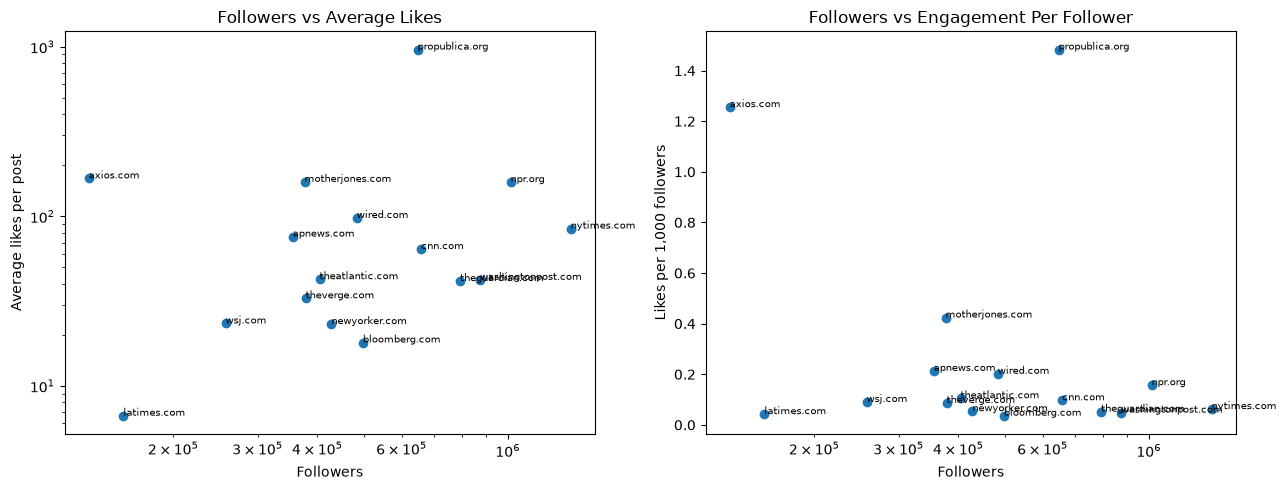

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(final_df["followers"], final_df["avg_likes"])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Followers")
axes[0].set_ylabel("Average likes per post")
axes[0].set_title("Followers vs Average Likes")

axes[1].scatter(final_df["followers"], final_df["likes_per_1k_followers"])
axes[1].set_xscale("log")
axes[1].set_xlabel("Followers")
axes[1].set_ylabel("Likes per 1,000 followers")
axes[1].set_title("Followers vs Engagement Per Follower")

for _, row in final_df.iterrows():
    axes[0].annotate(row["handle"], (row["followers"], row["avg_likes"]), fontsize=7)
    axes[1].annotate(row["handle"], (row["followers"], row["likes_per_1k_followers"]), fontsize=7)

plt.tight_layout()
plt.show()

## Conclusions

The data only partly supports the hypothesis. Follower count and average likes per post barely move together (a Spearman correlation of about 0.15), so the first part, that bigger outlets get more likes per post, doesn't really hold up. The New York Times has the most followers by far but averages fewer likes per post than smaller accounts like NPR, Mother Jones, and Axios. The second part looks a little better, since followers and likes per 1,000 followers have a weak negative relationship (about negative 0.24), and the outlets with the strongest engagement relative to their audience, ProPublica and Axios, are not the biggest ones.

Those two accounts are also the clearest example of why this needs more careful collection. Their 200 most recent posts stretch back weeks instead of days, so their posts have had more time to pile up likes while the high volume outlets are mostly being measured on posts from the last few days. That means posting frequency and post age may explain more of the differences here than audience size does. The averages are also pulled around by a few viral posts, since median likes lines up with followers more closely than the mean does (about 0.34 compared to 0.15), and Axios averages 167 likes per post even though its median is only 36.5. Overall the pattern hints that a big following doesn't guarantee strong engagement, but it's too weak and too affected by outliers to call the hypothesis confirmed.

## Limitations and Next Steps

This is a small, hand picked group of outlets and only their most recent posts, so the results can't really be generalized to news accounts on Bluesky as a whole. The lack of view counts is the biggest problem, since likes per follower assumes every follower had the same chance to see a post, which isn't true. Posting volume is also a confound, because an outlet that posts constantly will spread its engagement thin and look worse per post even if its audience is just as active.

A better version would use a larger set of outlets, collect posts from the same fixed date window for every account, and only count posts at least a few days old so their likes have settled. Adding posting frequency and whether posts include links or images as controls in a regression on log followers would help separate audience size from posting habits. Collecting the same accounts again over a few months would also show whether the pattern stays stable or shifts as Bluesky grows.